# EDA: Final_Marks_Data.csv

Charts for the analysis in `ml_training/eda.py`. Tables and conclusions are in `reports/eda_report.md`. Provenance of the dataset is unknown.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # backend/
import matplotlib.pyplot as plt
import pandas as pd
from app.ml.features import ATTENDANCE, INTERNAL1, INTERNAL2, ASSIGNMENT, TARGET, FEATURE_LABELS
from ml_training.dataset import load_raw, prepare
from ml_training.eda import analyse
raw = load_raw(); data = prepare(raw); summary = analyse()
FEATURES = [ATTENDANCE, INTERNAL1, INTERNAL2, ASSIGNMENT]
raw.head()

Matplotlib is building the font cache; this may take a moment.


,Student_ID,Attendance (%),Internal Test 1 (out of 40),Internal Test 2 (out of 40),Assignment Score (out of 10),Daily Study Hours,Final Exam Marks (out of 100)
0,S1000,84,30,36,7,3,72
1,S1001,91,24,38,6,3,56
2,S1002,73,29,26,7,3,56
3,S1003,80,36,35,7,3,74
4,S1004,84,31,37,8,3,66


## Data quality

In [2]:
pd.Series(summary['quality']).to_frame('value')

,value
missing_values_total,0
duplicate_student_ids,0
exact_duplicate_rows_excluding_id,3
rows_in_duplicate_groups_excluding_id,6
identical_inputs_with_different_targets_groups,56
all_values_integers,True
iqr_outliers_per_column,"{'Attendance (%)': 10, 'Internal Test 1 (out o..."


## Feature and target distributions (percent scale)

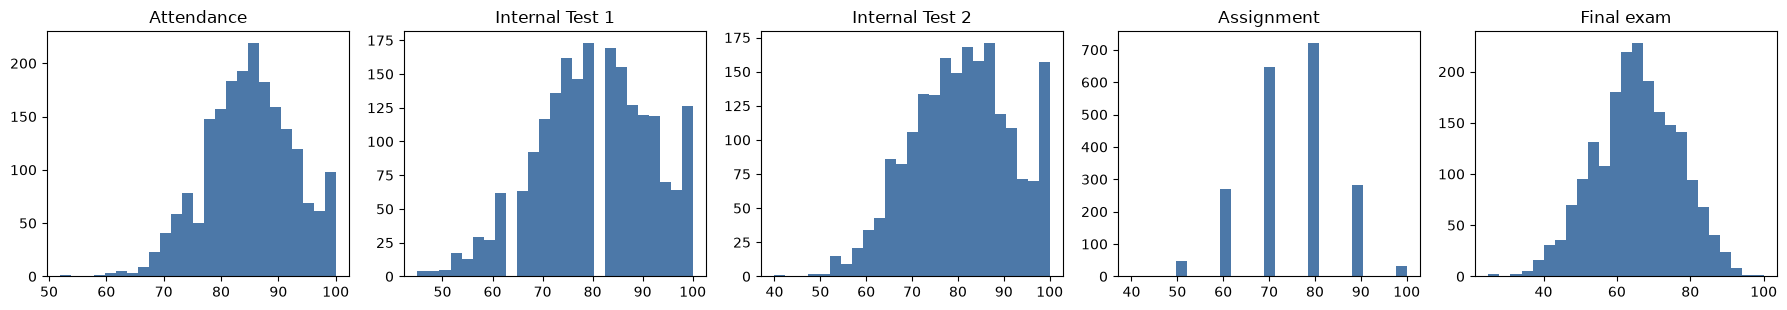

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, col in zip(axes, FEATURES + [TARGET]):
    ax.hist(data[col], bins=25, color='#4C78A8')
    ax.set_title(FEATURE_LABELS.get(col, 'Final exam'))
plt.tight_layout(); plt.show()

## Each feature against the final exam mark

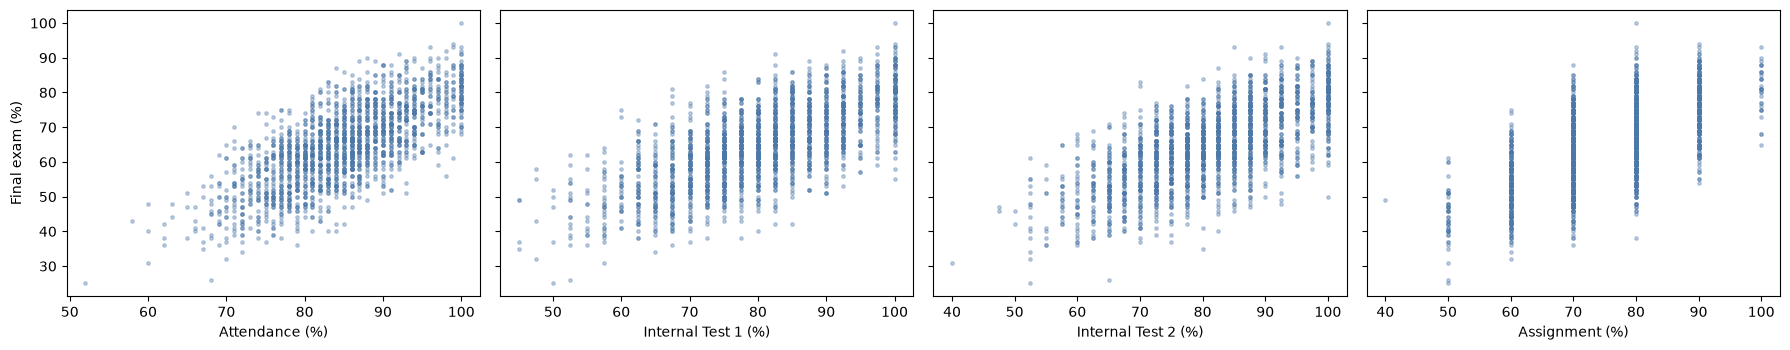

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, col in zip(axes, FEATURES):
    ax.scatter(data[col], data[TARGET], s=6, alpha=0.35, color='#4C78A8')
    ax.set_xlabel(FEATURE_LABELS[col] + ' (%)')
axes[0].set_ylabel('Final exam (%)'); plt.tight_layout(); plt.show()

## Correlations

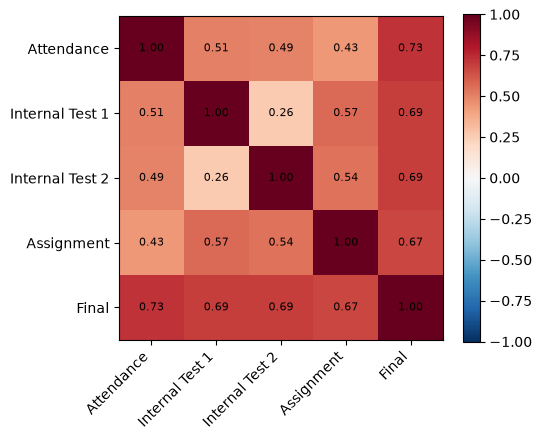

In [5]:
corr = data[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
labels = [FEATURE_LABELS.get(c, 'Final') for c in corr.columns]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right'); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im); plt.tight_layout(); plt.show()

## Mean final mark by attendance band

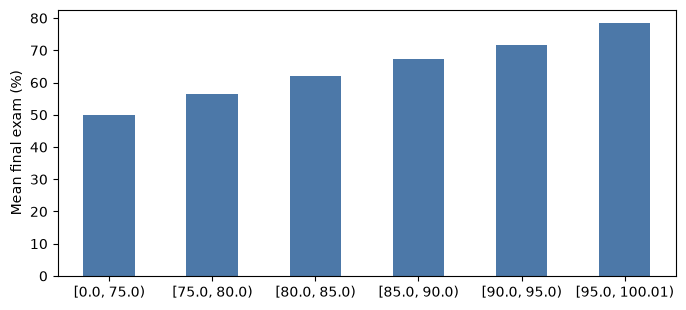

,n,mean_final
"[0.0, 75.0)",183.0,49.91
"[75.0, 80.0)",311.0,56.46
"[80.0, 85.0)",460.0,62.15
"[85.0, 90.0)",480.0,67.25
"[90.0, 95.0)",338.0,71.69
"[95.0, 100.01)",228.0,78.59


In [6]:
bands = pd.DataFrame(summary['target_mean_by_attendance_band']).T
ax = bands['mean_final'].plot.bar(color='#4C78A8', figsize=(7, 3.2), rot=0)
ax.set_ylabel('Mean final exam (%)'); plt.tight_layout(); plt.show(); bands

Associations only: these charts do not show that attendance or marks *cause* final results.